In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [2]:
real_news = pd.read_csv("True.csv")
fake_news = pd.read_csv("Fake.csv")

In [3]:
real_news["Category"] = "Real News"
fake_news["Category"] = "Fake News"

In [4]:
news = pd.concat([real_news, fake_news], ignore_index=True)


In [5]:
news["title"] = news["title"].fillna("")
news["text"] = news["text"].fillna("")

In [6]:
news["news_text"] = news["title"] + " " + news["text"]

news[["Category", "news_text"]].head()

,Category,news_text
0,Real News,"As U.S. budget fight looms, Republicans flip t..."
1,Real News,U.S. military to accept transgender recruits o...
2,Real News,Senior U.S. Republican senator: 'Let Mr. Muell...
3,Real News,FBI Russia probe helped by Australian diplomat...
4,Real News,Trump wants Postal Service to charge 'much mor...


In [7]:
# cal.. sentiment intensity
analyzer = SentimentIntensityAnalyzer()

news["sentiment_score"] = news["news_text"].apply(lambda text: analyzer.polarity_scores(text)["compound"])

news["sentiment_intensity"] = news["sentiment_score"].abs()

news[["Category", "sentiment_score", "sentiment_intensity"]].head()

,Category,sentiment_score,sentiment_intensity
0,Real News,0.9831,0.9831
1,Real News,-0.3941,0.3941
2,Real News,-0.6808,0.6808
3,Real News,-0.2201,0.2201
4,Real News,0.7157,0.7157


In [8]:
# measure emotional overuse
news["word_count"] = news["news_text"].str.findall(r"\b[a-zA-Z]+\b").str.len()

news[["news_text", "word_count"]].head()

,news_text,word_count
0,"As U.S. budget fight looms, Republicans flip t...",758
1,U.S. military to accept transgender recruits o...,641
2,Senior U.S. Republican senator: 'Let Mr. Muell...,475
3,FBI Russia probe helped by Australian diplomat...,396
4,Trump wants Postal Service to charge 'much mor...,858


In [9]:
# separate words
words = news["news_text"].str.lower().str.findall(r"\b[a-z]+\b").explode()

words.head(10)

0             as
0              u
0              s
0         budget
0          fight
0          looms
0    republicans
0           flip
0          their
0         fiscal
Name: news_text, dtype: object

In [10]:
# Identify emotional words
word_scores = words.map(analyzer.lexicon)

emotional_word_count = word_scores.abs().ge(2.0).groupby(level=0).sum()

news["emotional_word_count"] = emotional_word_count

news[["Category", "emotional_word_count"]].head()

,Category,emotional_word_count
0,Real News,3
1,Real News,13
2,Real News,4
3,Real News,6
4,Real News,5


In [11]:
news["emotional_words_per_100"] = (
    news["emotional_word_count"] / news["word_count"].replace(0, 1) * 100
)

news[["Category", "word_count", "emotional_word_count",
      "emotional_words_per_100"]].head()

,Category,word_count,emotional_word_count,emotional_words_per_100
0,Real News,758,3,0.395778
1,Real News,641,13,2.028081
2,Real News,475,4,0.842105
3,Real News,396,6,1.515152
4,Real News,858,5,0.582751


In [12]:
# compare real and fake news
comparison = news.groupby("Category").agg(
    Average_Sentiment_Intensity=("sentiment_intensity", "mean"),
    Average_Emotional_Words=("emotional_words_per_100", "mean")
)

comparison.round(3)

,Average_Sentiment_Intensity,Average_Emotional_Words
Category,,
Fake News,0.83,2.932
Real News,0.79,1.912


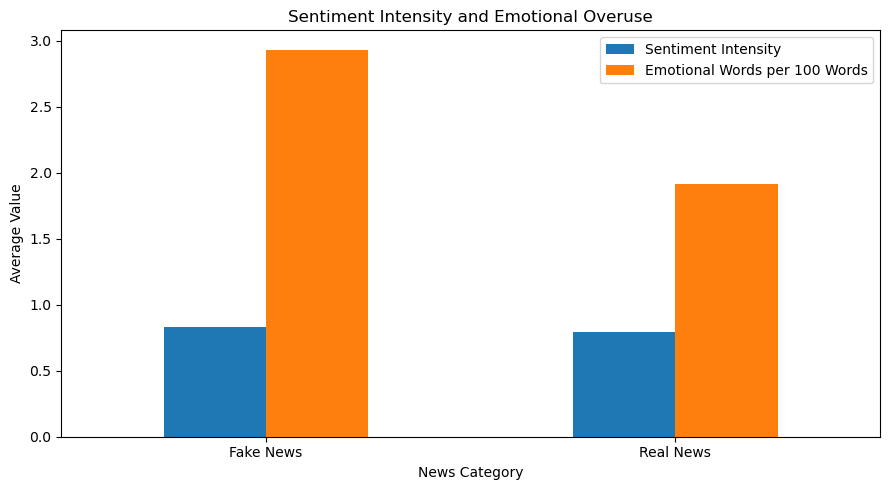

In [13]:
comparison.plot(kind="bar", figsize=(9, 5))

plt.title("Sentiment Intensity and Emotional Overuse")
plt.ylabel("Average Value")
plt.xlabel("News Category")
plt.xticks(rotation=0)
plt.legend(["Sentiment Intensity", "Emotional Words per 100 Words"])
plt.tight_layout()
plt.show()

In [14]:
real = comparison.loc["Real News"]
fake = comparison.loc["Fake News"]

if fake["Average_Sentiment_Intensity"] > real["Average_Sentiment_Intensity"]:
    print("Fake news has stronger average sentiment intensity.")
else:
    print("Real news has equal or stronger average sentiment intensity.")

if fake["Average_Emotional_Words"] > real["Average_Emotional_Words"]:
    print("Fake news uses more emotionally charged words per 100 words.")
else:
    print("Real news uses an equal or higher frequency of emotionally charged words.")

Fake news has stronger average sentiment intensity.
Fake news uses more emotionally charged words per 100 words.
